In [8]:
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

RANDOM_STATE = 42
pd.set_option("display.max_columns", 60)


In [9]:
from pathlib import Path
DATA_PATH = Path("Water Quality.csv")
if not DATA_PATH.exists():
    raise FileNotFoundError("Put 'Water Quality.csv' in the same folder as this notebook, or update DATA_PATH.")
df = pd.read_csv(DATA_PATH, low_memory=False)
print(f"Loaded {len(df):,} rows and {df.shape[1]} columns.")
display(df.head())


Loaded 229,916 rows and 40 columns.


,DatasetName,MonitoringLocationID,MonitoringLocationName,MonitoringLocationLatitude,MonitoringLocationLongitude,MonitoringLocationHorizontalCoordinateReferenceSystem,MonitoringLocationHorizontalAccuracyMeasure,MonitoringLocationHorizontalAccuracyUnit,MonitoringLocationVerticalMeasure,MonitoringLocationVerticalUnit,MonitoringLocationType,ActivityType,ActivityMediaName,ActivityStartDate,ActivityStartTime,ActivityEndDate,ActivityEndTime,ActivityDepthHeightMeasure,ActivityDepthHeightUnit,SampleCollectionEquipmentName,CharacteristicName,MethodSpeciation,ResultSampleFraction,ResultValue,ResultUnit,ResultValueType,ResultDetectionCondition,ResultDetectionQuantitationLimitMeasure,ResultDetectionQuantitationLimitUnit,ResultDetectionQuantitationLimitType,ResultStatusID,ResultComment,ResultAnalyticalMethodID,ResultAnalyticalMethodContext,ResultAnalyticalMethodName,AnalysisStartDate,AnalysisStartTime,AnalysisStartTimeZone,LaboratoryName,LaboratorySampleID
0,Maritime Coastal Basin Long-term Water Quality...,NS01ED0005,MERSEY RIVER BELOW MILL FALLS SOUTH-WEST OF MA...,44.4367,-65.2228,NAD83,NaN,NaN,NaN,NaN,River/Stream,Sample-Routine,Surface Water,2000-01-03,12:00:00,NaN,NaN,NaN,NaN,NaN,Aluminum,NaN,Extractable,254.70,ug/L,Actual,NaN,NaN,ug/L,NaN,Preliminary,NaN,110688,ENV/CANADA,NaN,NaN,NaN,NaN,ECCCLabs,NaN
1,Maritime Coastal Basin Long-term Water Quality...,NS01ED0005,MERSEY RIVER BELOW MILL FALLS SOUTH-WEST OF MA...,44.4367,-65.2228,NAD83,NaN,NaN,NaN,NaN,River/Stream,Sample-Routine,Surface Water,2000-01-03,12:00:00,NaN,NaN,NaN,NaN,NaN,Apparent color,NaN,NaN,133.00,TCU,Actual,NaN,NaN,TCU,NaN,Preliminary,NaN,2011,ENV/CANADA,NaN,NaN,NaN,NaN,ECCCLabs,NaN
2,Maritime Coastal Basin Long-term Water Quality...,NS01ED0005,MERSEY RIVER BELOW MILL FALLS SOUTH-WEST OF MA...,44.4367,-65.2228,NAD83,NaN,NaN,NaN,NaN,River/Stream,Sample-Routine,Surface Water,2000-01-03,12:00:00,NaN,NaN,NaN,NaN,NaN,Calcium,NaN,Dissolved,1.10,mg/L,Actual,NaN,NaN,mg/L,NaN,Preliminary,NaN,20110,ENV/CANADA,NaN,NaN,NaN,NaN,ECCCLabs,NaN
3,Maritime Coastal Basin Long-term Water Quality...,NS01ED0005,MERSEY RIVER BELOW MILL FALLS SOUTH-WEST OF MA...,44.4367,-65.2228,NAD83,NaN,NaN,NaN,NaN,River/Stream,Sample-Routine,Surface Water,2000-01-03,12:00:00,NaN,NaN,NaN,NaN,NaN,Chloride,NaN,Dissolved,6.13,mg/L,Actual,NaN,NaN,mg/L,NaN,Preliminary,NaN,17209,ENV/CANADA,NaN,NaN,NaN,NaN,ECCCLabs,NaN
4,Maritime Coastal Basin Long-term Water Quality...,NS01ED0005,MERSEY RIVER BELOW MILL FALLS SOUTH-WEST OF MA...,44.4367,-65.2228,NAD83,NaN,NaN,NaN,NaN,River/Stream,Sample-Routine,Surface Water,2000-01-03,12:00:00,NaN,NaN,NaN,NaN,NaN,Gran acid neutralizing capacity,NaN,NaN,-0.24,mg/L,Actual,NaN,NaN,mg/L,NaN,Preliminary,NaN,10110,ENV/CANADA,NaN,NaN,NaN,NaN,ECCCLabs,NaN


In [10]:
required = {"MonitoringLocationID", "ActivityStartDate", "CharacteristicName", "ResultValue"}
missing = required - set(df.columns)
if missing:
    raise ValueError(f"Missing required columns: {sorted(missing)}")

df["ActivityStartDate"] = pd.to_datetime(df["ActivityStartDate"], errors="coerce")
df["ResultValue"] = pd.to_numeric(df["ResultValue"], errors="coerce")
df["CharacteristicName"] = df["CharacteristicName"].astype("string").str.strip()
df["MonitoringLocationID"] = df["MonitoringLocationID"].astype("string").str.strip()
df = df.dropna(subset=["MonitoringLocationID", "ActivityStartDate", "CharacteristicName", "ResultValue"]).copy()
df["SampleDate"] = df["ActivityStartDate"].dt.floor("D")
print("Cleaned rows:", f"{len(df):,}")
print("Monitoring locations:", df["MonitoringLocationID"].nunique())
print("Date range:", df["ActivityStartDate"].min(), "to", df["ActivityStartDate"].max())


Cleaned rows: 229,916
Monitoring locations: 58
Date range: 2000-01-03 00:00:00 to 2023-12-06 00:00:00


In [11]:
TARGET_PARAMETER = "Specific conductance"
target_rows = df[df["CharacteristicName"].str.casefold() == TARGET_PARAMETER.casefold()].copy()
if target_rows.empty:
    candidates = sorted(x for x in df["CharacteristicName"].dropna().unique() if "conduct" in x.casefold())
    raise ValueError(f"Target '{TARGET_PARAMETER}' not found. Similar names: {candidates[:20]}")
print("Target records:", f"{len(target_rows):,}")
if "ResultUnit" in target_rows.columns:
    display(target_rows["ResultUnit"].value_counts(dropna=False).rename("Count").to_frame())


Target records: 8,963


,Count
ResultUnit,
uS/cm,8963


In [12]:
# Aggregate duplicate results for a location/date/parameter using the median.
wide = (
    df.groupby(["MonitoringLocationID", "SampleDate", "CharacteristicName"])["ResultValue"]
      .median()
      .unstack("CharacteristicName")
      .reset_index()
)
target_col = next((c for c in wide.columns if isinstance(c, str) and c.casefold() == TARGET_PARAMETER.casefold()), None)
if target_col is None:
    raise ValueError(f"Could not create target column '{TARGET_PARAMETER}'. Check spelling in CharacteristicName.")
wide = wide.sort_values(["SampleDate", "MonitoringLocationID"]).reset_index(drop=True)
print("Modelling table shape:", wide.shape)
display(wide.head())


Modelling table shape: (7283, 85)


CharacteristicName,MonitoringLocationID,SampleDate,"Alkalinity, total",Aluminum,Ammonia,Antimony,Apparent color,Arsenic,Barium,Beryllium,Bismuth,Boron,Bromine,Cadmium,Calcium,Cerium,Cesium,Chloride,"Chlorophyll a, uncorrected for pheophytin",Chromium,Cobalt,Conductivity,Copper,Depth of water column,Dissolved oxygen (DO),Dissolved oxygen saturation,Europium,Fecal Coliform,Fluoride,Gadolinium,...,Praseodymium,Rubidium,Samarium,Scandium,Selenium,Silicate,Silver,Sodium,Specific conductance,Strontium,Sulfate,Suspended Sediment Concentration (SSC),"Temperature, air","Temperature, water",Terbium,Thallium,Tin,Titanium,"Total Nitrogen, mixed forms","Total Phosphorus, mixed forms",True color,Tungsten,Turbidity,Uranium,Vanadium,Ytterbium,Yttrium,Zinc,Zirconium,pH
0,NS01ED0005,2000-01-03,NaN,254.7,NaN,NaN,133.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.10,NaN,NaN,6.13,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,4.20,39.3,NaN,2.14,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.14,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,4.75
1,NS01ED0110,2000-01-03,NaN,86.3,NaN,NaN,34.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.70,NaN,NaN,4.73,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3.14,29.3,NaN,2.51,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.07,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,5.15
2,NS01ED0111,2000-01-03,NaN,101.4,NaN,NaN,31.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.55,NaN,NaN,4.57,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2.79,27.0,NaN,1.95,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.10,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,5.11
3,NS01EE0014,2000-01-03,NaN,184.5,NaN,NaN,119.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.78,NaN,NaN,3.70,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2.79,31.6,NaN,2.40,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.10,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,4.61
4,NS01ED0005,2000-01-18,NaN,254.0,NaN,NaN,112.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.01,NaN,NaN,5.84,NaN,7.28,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3.71,37.8,NaN,2.20,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.12,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,4.65


In [13]:
numeric_cols = wide.select_dtypes(include=[np.number]).columns.tolist()
candidate_features = [
    c for c in numeric_cols
    if c != target_col and wide[c].notna().sum() >= max(30, int(0.10 * len(wide)))
]
model_data = wide.dropna(subset=[target_col]).sort_values("SampleDate").reset_index(drop=True).copy()
candidate_features = [c for c in candidate_features if c in model_data.columns]

if len(model_data) < 30:
    raise ValueError(f"Only {len(model_data)} dated target records available; need at least 30 for this demonstration.")
if not candidate_features:
    raise ValueError("No other parameters have enough matched observations as predictors. Try a different target or feature design.")

split_idx = int(len(model_data) * 0.80)
split_idx = min(max(split_idx, 1), len(model_data) - 1)
train, test = model_data.iloc[:split_idx].copy(), model_data.iloc[split_idx:].copy()
X_train, X_test = train[candidate_features], test[candidate_features]
y_train, y_test = train[target_col], test[target_col]

print("Predictors:", len(candidate_features))
print("Training rows:", len(train), "| Test rows:", len(test))
print("Train period:", train["SampleDate"].min(), "to", train["SampleDate"].max())
print("Test period:", test["SampleDate"].min(), "to", test["SampleDate"].max())
print("Features:", candidate_features)


Predictors: 46
Training rows: 5777 | Test rows: 1445
Train period: 2000-01-03 00:00:00 to 2017-09-12 00:00:00
Test period: 2017-09-14 00:00:00 to 2023-12-06 00:00:00
Features: ['Alkalinity, total', 'Aluminum', 'Antimony', 'Apparent color', 'Arsenic', 'Barium', 'Beryllium', 'Boron', 'Cadmium', 'Calcium', 'Chloride', 'Chromium', 'Cobalt', 'Copper', 'Dissolved oxygen (DO)', 'Dissolved oxygen saturation', 'Fluoride', 'Gallium', 'Gran acid neutralizing capacity', 'Inorganic carbon', 'Iron', 'Lanthanum', 'Lead', 'Lithium', 'Magnesium', 'Manganese', 'Molybdenum', 'Nickel', 'Nitrate', 'Organic carbon', 'Potassium', 'Rubidium', 'Selenium', 'Sodium', 'Strontium', 'Sulfate', 'Temperature, water', 'Tin', 'Titanium', 'Total Nitrogen, mixed forms', 'Total Phosphorus, mixed forms', 'Turbidity', 'Uranium', 'Vanadium', 'Zinc', 'pH']


In [14]:
baseline = DummyRegressor(strategy="median")
baseline.fit(np.zeros((len(y_train), 1)), y_train)
pred_baseline = baseline.predict(np.zeros((len(y_test), 1)))

linear_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("model", LinearRegression())
])
linear_model.fit(X_train, y_train)
pred_linear = linear_model.predict(X_test)

rf_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("model", RandomForestRegressor(
        n_estimators=300, min_samples_leaf=2, max_features=1.0,
        random_state=RANDOM_STATE, n_jobs=-1
    ))
])
rf_model.fit(X_train, y_train)
pred_rf = rf_model.predict(X_test)
print("All three models trained successfully.")


All three models trained successfully.


In [15]:
def regression_metrics(y_true, y_pred, model_name):
    return {
        "Model": model_name,
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "R2": r2_score(y_true, y_pred) if len(y_true) >= 2 else np.nan
    }

results = pd.DataFrame([
    regression_metrics(y_test, pred_baseline, "Median baseline"),
    regression_metrics(y_test, pred_linear, "Linear Regression"),
    regression_metrics(y_test, pred_rf, "Random Forest")
]).sort_values("RMSE")
display(results.round(4))
print("Lower MAE/RMSE is better. R² can be negative if predictions perform worse than the test-set mean.")


,Model,MAE,RMSE,R2
2,Random Forest,8.8586,38.9249,0.9415
1,Linear Regression,9.4841,39.2120,0.9406
0,Median baseline,73.3983,174.9632,-0.1817


Lower MAE/RMSE is better. R² can be negative if predictions perform worse than the test-set mean.


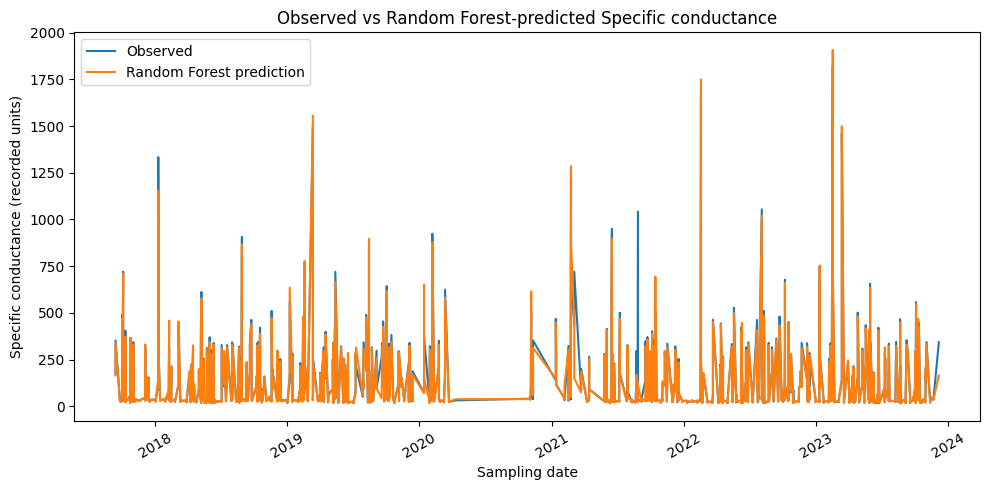

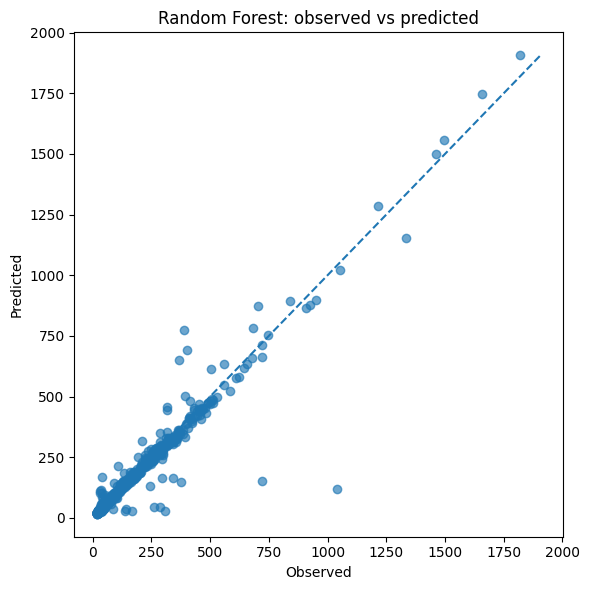

In [16]:
plt.figure(figsize=(10, 5))
plt.plot(test["SampleDate"], y_test.to_numpy(), label="Observed", linewidth=1.5)
plt.plot(test["SampleDate"], pred_rf, label="Random Forest prediction", linewidth=1.5)
plt.title(f"Observed vs Random Forest-predicted {TARGET_PARAMETER}")
plt.xlabel("Sampling date")
plt.ylabel(f"{TARGET_PARAMETER} (recorded units)")
plt.legend()
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

plt.figure(figsize=(6, 6))
plt.scatter(y_test, pred_rf, alpha=0.65)
low = min(float(np.min(y_test)), float(np.min(pred_rf)))
high = max(float(np.max(y_test)), float(np.max(pred_rf)))
plt.plot([low, high], [low, high], linestyle="--")
plt.title("Random Forest: observed vs predicted")
plt.xlabel("Observed")
plt.ylabel("Predicted")
plt.tight_layout()
plt.show()
